    Year  treat  kontrolle  differenz  effekt  rel
0   2010 -6.086     -6.987      0.900   0.003   -8
1   2011 -6.760     -7.146      0.387  -0.510   -7
2   2012 -6.367     -7.172      0.805  -0.092   -6
3   2013 -6.079     -7.074      0.995   0.098   -5
4   2014 -6.460     -7.054      0.594  -0.303   -4
5   2015 -6.223     -7.216      0.994   0.097   -3
6   2016 -6.199     -7.126      0.926   0.029   -2
7   2017 -6.273     -7.170      0.897   0.000   -1
8   2018 -6.488     -6.991      0.503  -0.394    0
9   2019 -6.392     -6.934      0.542  -0.355    1
10  2020 -6.277     -6.941      0.664  -0.233    2
11  2021 -6.901     -7.057      0.157  -0.740    3
12  2022 -6.593     -6.921      0.329  -0.568    4
13  2023 -6.742     -7.023      0.281  -0.616    5
14  2024 -6.870     -6.918      0.047  -0.850    6
15  2025 -7.011     -6.785     -0.226  -1.123    7


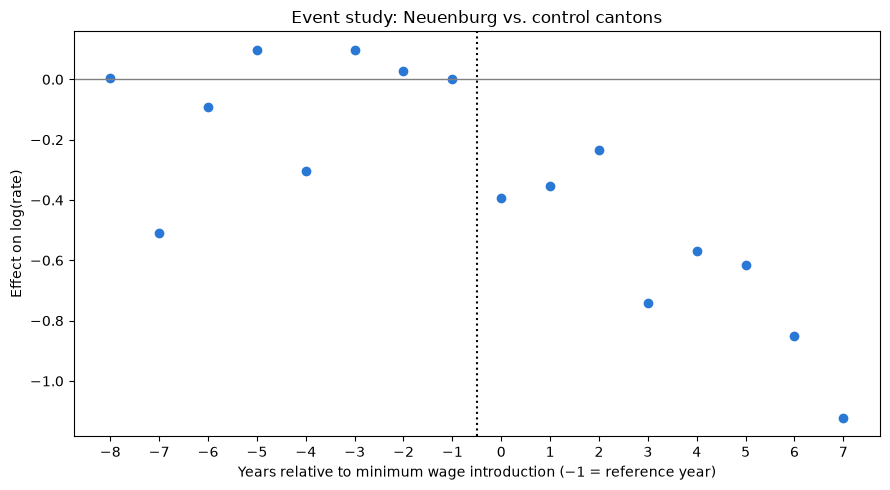

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MINDESTLOHN_KANTON = "Neuenburg"
KONTROLL_KANTONE   = ["Thurgau", "Wallis", "Bern", "Solothurn",
                      "St. Gallen", "Freiburg", "Aargau"]
EINFUEHRUNG        = 2018

df = pd.read_csv("Crime_Pop_clean_copy2.csv")
df["log_rate"] = np.log(df["Number of Accused Persons"] / df["Resident Population"])

# Schritt 1: log_rate des Mindestlohn-Kantons pro Jahr
treat = df[df["Canton"] == MINDESTLOHN_KANTON][["Year", "log_rate"]]
treat = treat.rename(columns={"log_rate": "treat"})

# Schritt 2: Durchschnitt der 7 Kontrollkantone pro Jahr
kontrolle = (df[df["Canton"].isin(KONTROLL_KANTONE)]
             .groupby("Year", as_index=False)["log_rate"].mean()
             .rename(columns={"log_rate": "kontrolle"}))

# Schritt 3: zusammenfügen und Differenz pro Jahr
es = treat.merge(kontrolle, on="Year")
es["differenz"] = es["treat"] - es["kontrolle"]

# Schritt 4: Differenz im Jahr vor der Einführung abziehen (Referenzjahr = 0)
referenz = es.loc[es["Year"] == EINFUEHRUNG - 1, "differenz"].iloc[0]
es["effekt"] = es["differenz"] - referenz
es["rel"] = es["Year"] - EINFUEHRUNG
print(es.round(3))

# Schritt 5: plotten
plt.figure(figsize=(9, 5))
plt.plot(es["rel"], es["effekt"], "o", color="#2a78d6")
plt.axhline(0, color="grey", linewidth=1)
plt.axvline(-0.5, color="black", linestyle=":")
plt.xticks(es["rel"])
plt.xlabel("Years relative to minimum wage introduction (−1 = reference year)")
plt.ylabel("Effect on log(rate)")
plt.title(f"Event study: {MINDESTLOHN_KANTON} vs. control cantons")
plt.tight_layout()
plt.show()

    Year  treat  kontrolle  differenz  effekt  rel
0   2010 -8.217     -6.987     -1.230  -0.089  -11
1   2011 -7.778     -7.146     -0.632   0.509  -10
2   2012 -7.511     -7.172     -0.340   0.801   -9
3   2013 -7.499     -7.074     -0.425   0.716   -8
4   2014 -7.786     -7.054     -0.732   0.408   -7
5   2015 -8.285     -7.216     -1.068   0.073   -6
6   2016 -8.126     -7.126     -1.000   0.141   -5
7   2017 -8.310     -7.170     -1.140   0.001   -4
8   2018 -8.443     -6.991     -1.452  -0.311   -3
9   2019 -7.905     -6.934     -0.971   0.170   -2
10  2020 -8.081     -6.941     -1.141   0.000   -1
11  2021 -8.361     -7.057     -1.304  -0.163    0
12  2022 -7.851     -6.921     -0.930   0.211    1
13  2023 -7.555     -7.023     -0.532   0.609    2
14  2024 -8.053     -6.918     -1.135   0.006    3
15  2025 -8.338     -6.785     -1.553  -0.413    4


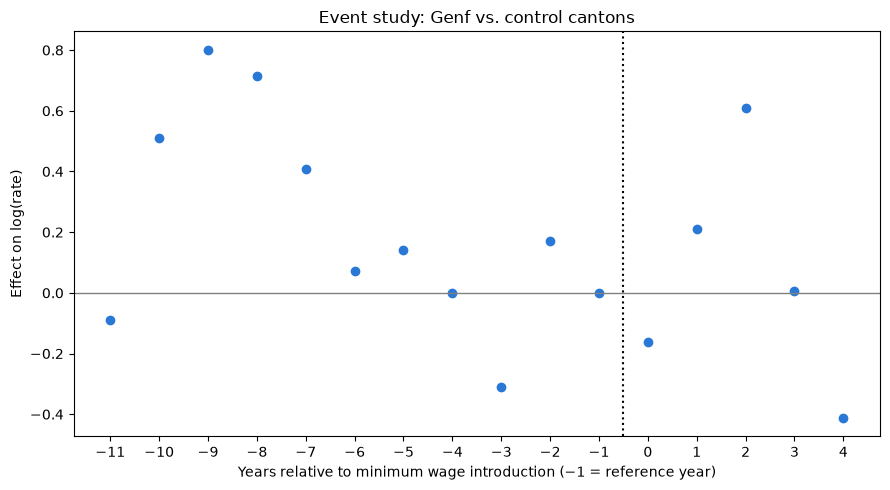

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MINDESTLOHN_KANTON = "Genf"
KONTROLL_KANTONE   = ["Thurgau", "Wallis", "Bern", "Solothurn",
                      "St. Gallen", "Freiburg", "Aargau"]
EINFUEHRUNG        = 2021

df = pd.read_csv("Crime_Pop_clean_copy2.csv")
df["log_rate"] = np.log(df["Number of Accused Persons"] / df["Resident Population"])

# Schritt 1: log_rate des Mindestlohn-Kantons pro Jahr
treat = df[df["Canton"] == MINDESTLOHN_KANTON][["Year", "log_rate"]]
treat = treat.rename(columns={"log_rate": "treat"})

# Schritt 2: Durchschnitt der 7 Kontrollkantone pro Jahr
kontrolle = (df[df["Canton"].isin(KONTROLL_KANTONE)]
             .groupby("Year", as_index=False)["log_rate"].mean()
             .rename(columns={"log_rate": "kontrolle"}))

# Schritt 3: zusammenfügen und Differenz pro Jahr
es = treat.merge(kontrolle, on="Year")
es["differenz"] = es["treat"] - es["kontrolle"]

# Schritt 4: Differenz im Jahr vor der Einführung abziehen (Referenzjahr = 0)
referenz = es.loc[es["Year"] == EINFUEHRUNG - 1, "differenz"].iloc[0]
es["effekt"] = es["differenz"] - referenz
es["rel"] = es["Year"] - EINFUEHRUNG
print(es.round(3))

# Schritt 5: plotten
plt.figure(figsize=(9, 5))
plt.plot(es["rel"], es["effekt"], "o", color="#2a78d6")
plt.axhline(0, color="grey", linewidth=1)
plt.axvline(-0.5, color="black", linestyle=":")
plt.xticks(es["rel"])
plt.xlabel("Years relative to minimum wage introduction (−1 = reference year)")
plt.ylabel("Effect on log(rate)")
plt.title(f"Event study: {MINDESTLOHN_KANTON} vs. control cantons")
plt.tight_layout()
plt.show()

    Year  treat  kontrolle  differenz  effekt  rel
0   2010 -5.652     -6.987      1.335   0.183  -13
1   2011 -5.822     -7.146      1.324   0.172  -12
2   2012 -5.760     -7.172      1.411   0.259  -11
3   2013 -6.270     -7.074      0.804  -0.348  -10
4   2014 -6.011     -7.054      1.043  -0.109   -9
5   2015 -5.959     -7.216      1.257   0.105   -8
6   2016 -6.104     -7.126      1.022  -0.131   -7
7   2017 -5.879     -7.170      1.290   0.138   -6
8   2018 -5.945     -6.991      1.046  -0.106   -5
9   2019 -5.853     -6.934      1.081  -0.071   -4
10  2020 -5.937     -6.941      1.003  -0.149   -3
11  2021 -5.667     -7.057      1.390   0.238   -2
12  2022 -5.769     -6.921      1.152   0.000   -1
13  2023 -5.979     -7.023      1.044  -0.108    0
14  2024 -6.164     -6.918      0.753  -0.399    1
15  2025 -6.421     -6.785      0.363  -0.789    2


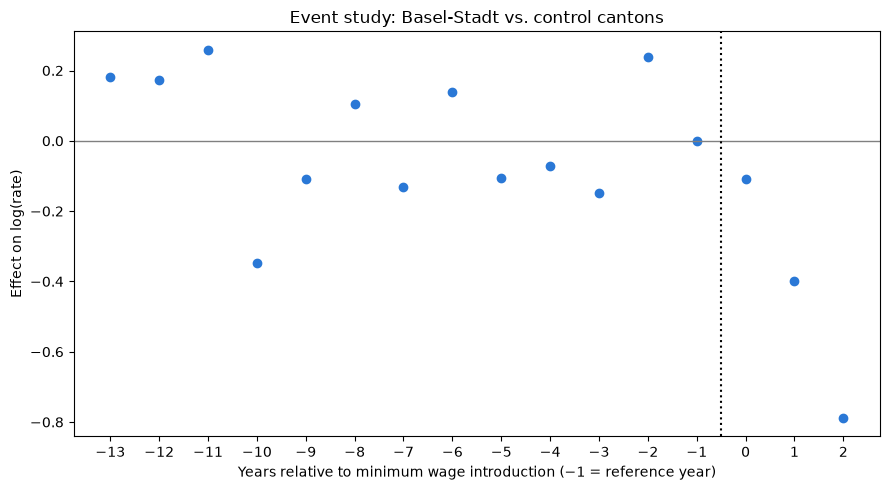

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MINDESTLOHN_KANTON = "Basel-Stadt"
KONTROLL_KANTONE   = ["Thurgau", "Wallis", "Bern", "Solothurn",
                      "St. Gallen", "Freiburg", "Aargau"]
EINFUEHRUNG        = 2023

df = pd.read_csv("Crime_Pop_clean_copy2.csv")
df["log_rate"] = np.log(df["Number of Accused Persons"] / df["Resident Population"])

# Schritt 1: log_rate des Mindestlohn-Kantons pro Jahr
treat = df[df["Canton"] == MINDESTLOHN_KANTON][["Year", "log_rate"]]
treat = treat.rename(columns={"log_rate": "treat"})

# Schritt 2: Durchschnitt der 7 Kontrollkantone pro Jahr
kontrolle = (df[df["Canton"].isin(KONTROLL_KANTONE)]
             .groupby("Year", as_index=False)["log_rate"].mean()
             .rename(columns={"log_rate": "kontrolle"}))

# Schritt 3: zusammenfügen und Differenz pro Jahr
es = treat.merge(kontrolle, on="Year")
es["differenz"] = es["treat"] - es["kontrolle"]

# Schritt 4: Differenz im Jahr vor der Einführung abziehen (Referenzjahr = 0)
referenz = es.loc[es["Year"] == EINFUEHRUNG - 1, "differenz"].iloc[0]
es["effekt"] = es["differenz"] - referenz
es["rel"] = es["Year"] - EINFUEHRUNG
print(es.round(3))

# Schritt 5: plotten
plt.figure(figsize=(9, 5))
plt.plot(es["rel"], es["effekt"], "o", color="#2a78d6")
plt.axhline(0, color="grey", linewidth=1)
plt.axvline(-0.5, color="black", linestyle=":")
plt.xticks(es["rel"])
plt.xlabel("Years relative to minimum wage introduction (−1 = reference year)")
plt.ylabel("Effect on log(rate)")
plt.title(f"Event study: {MINDESTLOHN_KANTON} vs. control cantons")
plt.tight_layout()
plt.show()